<div style="
    background-color: #7BAFD4;
    border-radius: 18px;
    padding: 22px 26px;
    display: flex;
    align-items: center;
    gap: 24px;
    margin-bottom: 18px;
">
    <img src="../592_avatar_lr.png" alt="GEOG 592"
        style="width:110px;height:110px;border-radius:22px;">
    <div>
        <div style="
            font-family: Impact, 'Arial Black', Arial, sans-serif;
            font-size: 42px;
            font-weight: 900;
            letter-spacing: 2px;
            line-height: 1;
            color: white;
        ">GEOG 592</div>
        <div style="
            font-family: Arial, Helvetica, sans-serif;
            font-size: 22px;
            font-weight: 700;
            color: #13294B;
            margin-top: 8px;
        ">GIS Programming</div>
        <div style="
            font-family: Arial, Helvetica, sans-serif;
            font-size: 16px;
            color: #13294B;
            margin-top: 6px;
        ">NC County Labelling Practice</div>
    </div>
</div>

In [40]:
# Importing packages
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

In [41]:
# Loading data 
# Source: https://www.nconemap.gov/datasets/nconemap::north-carolina-voting-polling-places/about
polling_places = gpd.read_file("North_Carolina_Voting_Polling_Places.geojson")
counties = gpd.read_file("https://www2.census.gov/geo/tiger/GENZ2024/shp/cb_2024_us_county_500k.zip")

In [42]:
# Pulling out just NC counties
nc_counties = counties.loc[counties["STATEFP"] == "37"].copy()

# Changing the CRS
ncc = nc_counties.to_crs(epsg=6543)
polling_places = polling_places.to_crs(epsg=6543)

In [43]:
ncc.head(2)

,STATEFP,COUNTYFP,COUNTYNS,GEOIDFQ,GEOID,NAME,NAMELSAD,STUSPS,STATE_NAME,LSAD,ALAND,AWATER,geometry
90,37,047,01026339,0500000US37047,37047,Columbus,Columbus County,NC,North Carolina,06,2429920494,43711694,"POLYGON ((1978481.879 199930.366, 1979179.073 ..."
91,37,039,01008545,0500000US37039,37039,Cherokee,Cherokee County,NC,North Carolina,06,1179842036,28813680,"POLYGON ((408779.421 505506.597, 408786.42 505..."


In [44]:
polling_places.head(2)

,FID,Status,Score,Match_type,Match_addr,Addr_type,Place_addr,Side,StPreDir,StPreType,...,USER_polli,USER_pol_1,USER_preci,USER_house,USER_stree,USER_addre,USER_city,USER_state,USER_zip,geometry
0,1,T,99.55,A,"621 E Haggard Ave, Elon, North Carolina, 27244",StreetAddress,"621 E Haggard Ave, Elon, North Carolina, 27244",R,E,,...,12,FIRST BAPTIST CHURCH OF ELON,NORTH BOONE,621,HAGGARD AVE,621 HAGGARD AVE,ELON,NC,27244,POINT (1853259.616 857054.995)
1,2,M,100.00,A,"810 Wicker St, Burlington, North Carolina, 27217",StreetAddress,"810 Wicker St, Burlington, North Carolina, 27217",L,,,...,10,ELMIRA COMMUNITY CENTER,BURLINGTON 7,810,WICKER ST,810 WICKER ST,BURLINGTON,NC,27217,POINT (1869425.883 858154.04)


In [45]:
# Filtering for only important columns. 
ncc = ncc[["GEOID", "NAME", "geometry"]]
polling_places = polling_places[["USER_pol_1", "USER_addre", "USER_city", "USER_zip","geometry"]]

# And renaming 
ncc = ncc.rename(columns={"GEOID":"geoid", "NAME":"name"})
polling_places = polling_places.rename(columns={"USER_pol_1":"poll_name", "USER_addre":"address", "USER_city":"city",
                       "USER_zip":"zip"})

In [85]:
# Joining the polling places to the counties 
ncc_polls = gpd.sjoin(ncc, polling_places, predicate="contains", how="right")

# Dropping the right index 
ncc_polls = ncc_polls.drop(columns="index_left")

ncc_polls.head()

,geoid,name,poll_name,address,city,zip,geometry
0,37001,Alamance,FIRST BAPTIST CHURCH OF ELON,621 HAGGARD AVE,ELON,27244,POINT (1853259.616 857054.995)
1,37001,Alamance,ELMIRA COMMUNITY CENTER,810 WICKER ST,BURLINGTON,27217,POINT (1869425.883 858154.04)
2,37001,Alamance,LAKEVIEW COMMUNITY CHURCH,101 BOONE RD,BURLINGTON,27217,POINT (1875088.197 875880.048)
3,37001,Alamance,FELLOWSHIP BAPTIST CHURCH,2744 MAPLE AVE,BURLINGTON,27215,POINT (1871745.088 840379.025)
4,37001,Alamance,ALAMANCE CIVITAN CLUB HOUSE,3328 DOCTOR PICKETT RD,BURLINGTON,27215,POINT (1869971.902 851187.31)


In [47]:
# Sort counties alphabetically 
ncc_polls = ncc_polls.sort_values("name").reset_index(drop=True)

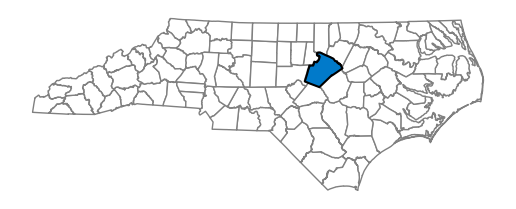

In [127]:
# Creating NC map with selected county highlighted.
def highlight(name, ax):
    # Pulling out just the row for that county. 
    selected = ncc[ncc["name"] == name]
    # Creating an axes object. 
    ncc.plot(ax=ax, edgecolor="grey", facecolor="white")
    # Adding an element onto that axes object. 
    selected.plot(ax=ax, edgecolor="#000000", facecolor="#017aca", lw=1.5)
    ax.set_axis_off()

# Example 
fig, ax = plt.subplots()
highlight("Wake", ax)

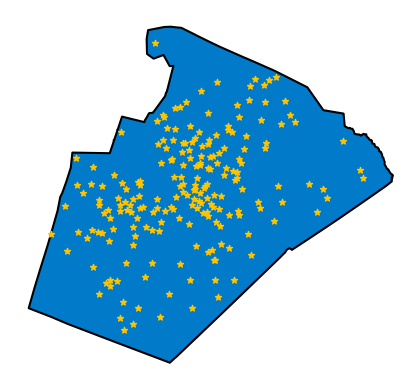

In [128]:
# Map with just county.
def county_map(name, ax):
    selected = ncc[ncc["name"] == name]
    selected.plot(ax=ax, edgecolor="#000000", facecolor="#017aca", lw=1.5)

    # Plotting polling places 
    county_polls = ncc_polls[ncc_polls["name"] == name]
    county_polls.plot(ax=ax, color="#FFC400", markersize=20, marker="*")

    ax.set_axis_off()

# Example 
fig, ax = plt.subplots()
county_map("Wake", ax)

In [122]:
# Text generator - summary of polling places. 

def summary(name): 
    county_polls = ncc_polls[ncc_polls["name"] == name]
    quantity = f"{name} County has {len(county_polls)} polling places."
    return quantity

summary("Wake")

'Wake County has 206 polling places.'

In [ ]:
# List of polling places. 

```python 
def county_figure(county, pdf):
    fig, axes = plt.subplots(
        2, 1,
        figsize=(8, 10),
        gridspec_kw={"height_ratios": [3, 1]}
    )

    county_map(county, axes[0])
    locator_map(county, axes[1])

    fig.suptitle(f"{county} County", fontsize=20)

    pdf.savefig(fig)
    plt.close(fig)

Text(0.5, 0.93, 'Wake County has 206 polling places.')

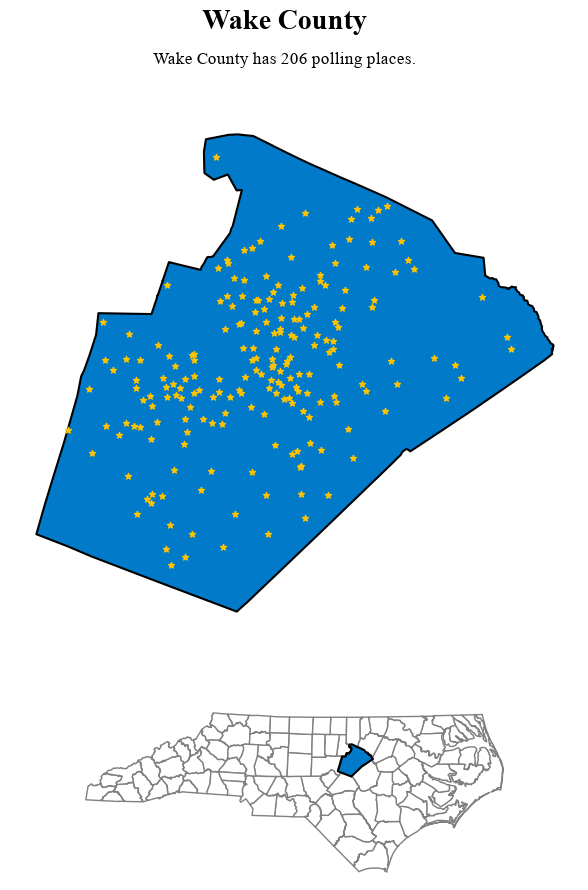

In [151]:
# Testing the arrangment

fig, axes = plt.subplots(
    2, 1,
    figsize=(8,10),
    gridspec_kw={"height_ratios": [3, 1]}
)

county_map("Wake", axes[0])
highlight("Wake", axes[1])

fig.suptitle("Wake County", fontsize=20, fontname="Times New Roman", fontweight="bold")
fig.text(0.5, 0.93, summary("Wake"), fontname="Times New Roman", ha="center", va="center", fontsize=12)

In [153]:
# A function to create each page by combining the elements.
def page(county, pdf):
    fig, axes = plt.subplots(
        2, 1,
        figsize=(8,10),
        gridspec_kw={"height_ratios": [3, 1]}
    )

    county_map(county, axes[0])
    highlight(county, axes[1])

    fig.suptitle(f"{county} County", fontname="Times New Roman", ha="center", va="center", fontsize=12)
    fig.text(0.5, 0.93, summary(county), fontname="Times New Roman", ha="center", va="center", fontsize=12)

    pdf.savefig(fig)
    plt.close(fig)

Iterate through all of the counties and create a page for each. 
```python
with PdfPages("NC_Counties.pdf") as pdf:  #with #manages a resource and automatically cleans up when you finish using it.
    for county in nc_counties["NAME"]:
        county_figure(county, pdf)
```

Iterate through ncc that has the list of counties without duplicates \
But the polling information uses ncc_polls 

In [143]:
from matplotlib.backends.backend_pdf import PdfPages 
with PdfPages("nc_polls.pdf") as pdf:  #with #manages a resource and automatically cleans up when you finish using it.
    for county in ncc["name"]:
        page(county, pdf)